# Credit Card Fraud Detection



In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score, recall_score,
                             f1_score, roc_curve, roc_auc_score, average_precision_score,
                             mutual_info_score)

sns.set_style("whitegrid")
%matplotlib inline

## Data preparation 

In [4]:
df = pd.read_csv("credit_card_fraud_2026.csv")
print(df.shape)
df.head().T

(20000, 26)


,0,1,2,3,4
transaction_id,1,2,3,4,5
amount_usd,42.86,4.75,77.18,1.69,261.68
merchant_category,Restaurants,Online Retail,Groceries,Streaming,Travel
card_type,Visa,Mastercard,Mastercard,Visa,Visa
auth_method,OTP,3D Secure,3D Secure,No Authentication,3D Secure
channel,Online,Online,Online,POS,In-App
device_type,Android Phone,Android Phone,Mac,Android Phone,iPhone
is_foreign_transaction,False,False,False,False,False
hours_since_last_txn,13.54,0.71,0.35,3.42,2.43
txn_count_last_24h,2,2,5,6,2


In [5]:
df.dtypes

transaction_id                    int64
amount_usd                      float64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
is_ai_generated_scam_attempt       bool
merchant_risk_score             float64
prior_disputes                    int64


Cleaning the data

In [6]:
df.columns = df.columns.str.lower().str.replace(" ", "_")
df = df.drop(columns=["transaction_id"])

bool_cols = df.select_dtypes(include="bool").columns.tolist()
df[bool_cols] = df[bool_cols].astype(int)

target = "is_fraud"
categorical = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
for c in categorical:
    df[c] = df[c].str.lower().str.replace(" ", "_")

numerical = [c for c in df.columns if c not in categorical + [target]]

print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(f"{len(numerical)} numerical (incl. {len(bool_cols)} yes/no flags), {len(categorical)} categorical")

Missing values: 0
Duplicate rows: 0
19 numerical (incl. 6 yes/no flags), 5 categorical


##  Exploratory data analysis 

### 2.1 Missing values and target distribution

In [7]:
print("Missing values per column:", df.isnull().sum().sum())
print()
print(df[target].value_counts())
print()
global_fraud = df[target].mean()
print(f"Global fraud rate: {global_fraud:.4f}")
print(f"Accuracy of a model that always says 'legitimate': {1 - global_fraud:.4f}")

Missing values per column: 0

is_fraud
0    19661
1      339
Name: count, dtype: int64

Global fraud rate: 0.0169
Accuracy of a model that always says 'legitimate': 0.9830


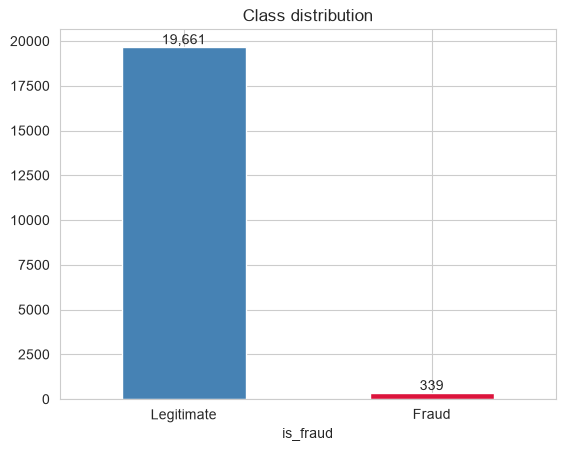

In [8]:
counts = df[target].value_counts()
ax = counts.plot(kind="bar", color=["steelblue", "crimson"])
ax.set_xticklabels(["Legitimate", "Fraud"], rotation=0)
ax.set_title("Class distribution")
for i, v in enumerate(counts):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.show()

###  Feature importance

In [9]:
binary = [c for c in numerical if df[c].nunique() == 2]
group_cols = categorical + binary

def risk_table(col):
    t = df.groupby(col)[target].agg(["mean", "count"])
    t["diff"] = t["mean"] - global_fraud
    t["risk"] = t["mean"] / global_fraud
    return t.sort_values("mean", ascending=False).round(3)

for c in categorical:
    print(c)
    display(risk_table(c))

merchant_category


,mean,count,diff,risk
merchant_category,,,,
crypto_exchange,0.050,561,0.033,2.945
gift_cards,0.044,617,0.027,2.582
gaming,0.037,1036,0.020,2.164
electronics,0.024,2032,0.007,1.394
streaming,0.021,1010,0.004,1.227
utilities,0.019,1330,0.002,1.109
healthcare,0.013,1237,-0.004,0.763
groceries,0.012,3242,-0.005,0.728
fuel,0.012,1565,-0.005,0.716


card_type


,mean,count,diff,risk
card_type,,,,
amex,0.020,2135,0.003,1.188
discover,0.020,1023,0.003,1.153
visa,0.018,8417,0.001,1.051
mastercard,0.015,6629,-0.002,0.908
rupay,0.013,1796,-0.004,0.788


auth_method


,mean,count,diff,risk
auth_method,,,,
no_authentication,0.044,2388,0.027,2.619
otp,0.016,4792,-0.001,0.923
3d_secure,0.015,5554,-0.001,0.914
pin,0.012,4173,-0.005,0.679
biometric,0.008,3093,-0.009,0.458


channel


,mean,count,diff,risk
channel,,,,
online,0.020,6810,0.003,1.170
atm,0.018,1374,0.001,1.073
in-app,0.016,3225,-0.001,0.951
pos,0.015,5191,-0.002,0.898
contactless,0.014,3400,-0.003,0.833


device_type


,mean,count,diff,risk
device_type,,,,
tablet,0.019,1161,0.002,1.118
android_phone,0.019,5503,0.002,1.115
mac,0.018,1359,0.001,1.085
atm_machine,0.018,1005,0.001,1.057
smart_watch,0.018,1008,0.001,1.054
pos_terminal,0.017,3162,0.000,1.008
iphone,0.017,4179,-0.000,0.974
windows_pc,0.011,2623,-0.006,0.652


In [10]:
for c in binary:
    print(c)
    display(risk_table(c))

is_foreign_transaction


,mean,count,diff,risk
is_foreign_transaction,,,,
1,0.059,1240,0.042,3.473
0,0.014,18760,-0.003,0.837


is_new_merchant


,mean,count,diff,risk
is_new_merchant,,,,
1,0.035,4601,0.018,2.064
0,0.012,15399,-0.005,0.682


used_vpn


,mean,count,diff,risk
used_vpn,,,,
1,0.044,1759,0.027,2.583
0,0.014,18241,-0.003,0.847


... (2 outputs left out)

billing_shipping_mismatch


,mean,count,diff,risk
billing_shipping_mismatch,,,,
1,0.078,873,0.061,4.595
0,0.014,19127,-0.003,0.836


is_ai_generated_scam_attempt


,mean,count,diff,risk
is_ai_generated_scam_attempt,,,,
1,0.091,375,0.074,5.349
0,0.016,19625,-0.001,0.917


### 2.3 Mutual information for categorical features

In [11]:
def mi_score(series):
    return mutual_info_score(series, df[target])

mi = df[group_cols].apply(mi_score).sort_values(ascending=False)
mi.round(4)

ip_country_mismatch             0.0039
billing_shipping_mismatch       0.0028
auth_method                     0.0026
is_new_merchant                 0.0025
merchant_category               0.0024
is_foreign_transaction          0.0022
is_ai_generated_scam_attempt    0.0016
used_vpn                        0.0015
device_type                     0.0002
channel                         0.0002
card_type                       0.0001
dtype: float64

### 2.4 Correlation for numerical features

In [12]:
count_like = ["cvv_retry_count", "prior_disputes", "txn_count_last_24h"]
numeric_only = [c for c in numerical if c not in binary]

corr = df[numeric_only + [target]].corr()[target].drop(target)
corr.reindex(corr.abs().sort_values(ascending=False).index).round(3)

cvv_retry_count          0.156
merchant_risk_score      0.108
velocity_score           0.097
txn_count_last_24h       0.060
time_of_day_hour        -0.031
hours_since_last_txn    -0.029
amount_usd               0.025
prior_disputes           0.024
customer_age             0.020
card_age_months         -0.012
day_of_week              0.006
account_balance_usd      0.004
distance_from_home_km   -0.004
Name: is_fraud, dtype: float64

In [13]:
for c in count_like:
    print(c)
    display(df.groupby(c)[target].agg(["mean", "count"]).round(3).T)

cvv_retry_count


cvv_retry_count,0,1,2,3
mean,0.009,0.047,0.161,0.133
count,16658.000,3073.000,254.000,15.000


prior_disputes


prior_disputes,0,1,2,3,4
mean,0.016,0.019,0.038,0.0,0.333
count,15085.000,4271.000,581.000,60.0,3.000


txn_count_last_24h


txn_count_last_24h,0,1,2,3,4,5,6,7,8,9,10,11,12
mean,0.005,0.008,0.012,0.017,0.017,0.026,0.028,0.027,0.039,0.027,0.16,0.2,1.0
count,770.000,2692.000,4194.000,4406.000,3569.000,2319.000,1164.000,550.000,232.000,73.000,25.00,5.0,1.0


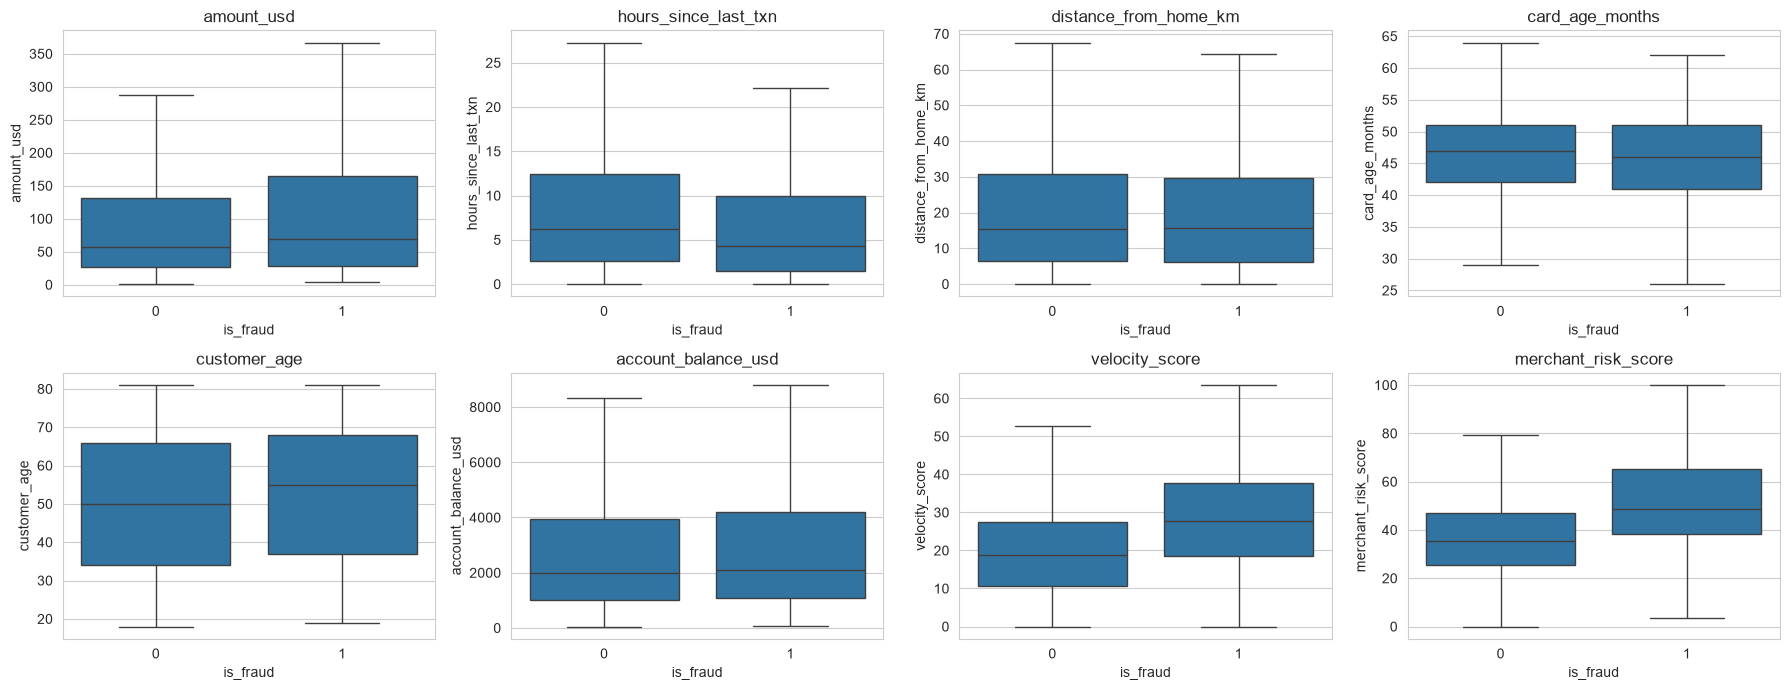

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
continuous = ["amount_usd", "hours_since_last_txn", "distance_from_home_km", "card_age_months",
              "customer_age", "account_balance_usd", "velocity_score", "merchant_risk_score"]
for ax, c in zip(axes.ravel(), continuous):
    sns.boxplot(data=df, x=target, y=c, ax=ax, showfliers=False)
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [15]:
# Fraud rate per fifth (quintile) of the strongest numeric features
for c in ["velocity_score", "merchant_risk_score", "hours_since_last_txn", "amount_usd"]:
    bins = pd.qcut(df[c], 5, duplicates="drop")
    print(c, df.groupby(bins, observed=True)[target].mean().round(3).tolist())

velocity_score [0.004, 0.009, 0.016, 0.018, 0.038]
merchant_risk_score [0.006, 0.006, 0.012, 0.022, 0.039]
hours_since_last_txn [0.025, 0.019, 0.013, 0.016, 0.012]
amount_usd [0.016, 0.013, 0.016, 0.018, 0.022]


###  Single-feature ROC AUC 

In [16]:
auc_scores = {c: roc_auc_score(df[target], df[c]) for c in numerical}
auc_scores = pd.Series(auc_scores).apply(lambda a: max(a, 1 - a)).sort_values(ascending=False)
auc_scores.head(10).round(3)

merchant_risk_score          0.713
cvv_retry_count              0.701
velocity_score               0.693
is_new_merchant              0.625
txn_count_last_24h           0.620
ip_country_mismatch          0.607
hours_since_last_txn         0.582
billing_shipping_mismatch    0.580
is_foreign_transaction       0.578
used_vpn                     0.571
dtype: float64

##  Setting up the validation framework 


In [17]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

for name, d in [("train", df_train), ("validation", df_val), ("test", df_test)]:
    print(f"{name:10s} rows={len(d):6d}  frauds={d[target].sum():4d}  fraud rate={d[target].mean():.4f}")

train      rows= 12000  frauds= 225  fraud rate=0.0187
validation rows=  4000  frauds=  52  fraud rate=0.0130
test       rows=  4000  frauds=  62  fraud rate=0.0155


In [18]:
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_full_train = df_full_train[target].values
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

for d in (df_full_train, df_train, df_val, df_test):
    del d[target]

## one-hot encoding


In [19]:
dv = DictVectorizer(sparse=False)

train_dict = df_train.to_dict(orient="records")
X_train = dv.fit_transform(train_dict)

val_dict = df_val.to_dict(orient="records")
X_val = dv.transform(val_dict)

print(X_train.shape, X_val.shape)
list(dv.get_feature_names_out())[:10]

(12000, 54) (4000, 54)


['account_balance_usd',
 'amount_usd',
 'auth_method=3d_secure',
 'auth_method=biometric',
 'auth_method=no_authentication',
 'auth_method=otp',
 'auth_method=pin',
 'billing_shipping_mismatch',
 'card_age_months',
 'card_type=amex']

##  Logistic regression baseline 

In [20]:
model = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=1)
model.fit(X_train, y_train)

y_pred_proba = model.predict_proba(X_val)[:, 1]     # probability of fraud
fraud_decision = (y_pred_proba >= 0.5)              # hard decision at threshold 0.5

print("Accuracy:", round((fraud_decision == y_val).mean(), 4))
print("Accuracy of 'always legitimate':", round(1 - y_val.mean(), 4))

Accuracy: 0.9848
Accuracy of 'always legitimate': 0.987


##  Evaluation metrics 

###  Confusion matrix, precision, recall

In [21]:
def evaluate(y_true, y_score, threshold=0.5):
    y_pred = (y_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score),
        "pr_auc": average_precision_score(y_true, y_score),
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }

res = evaluate(y_val, y_pred_proba)
pd.Series(res).round(3)

accuracy        0.985
precision       0.286
recall          0.115
f1              0.164
roc_auc         0.925
pr_auc          0.210
tp              6.000
fp             15.000
fn             46.000
tn           3933.000
dtype: float64

### 6.2 ROC curve and AUC

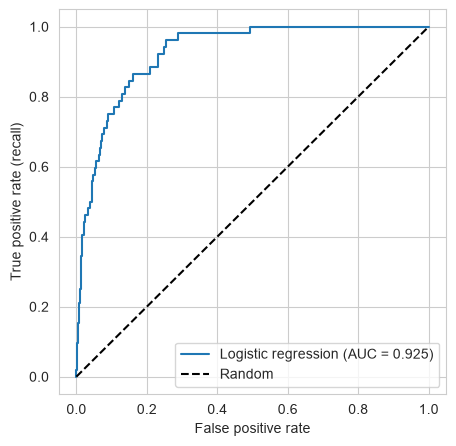

In [22]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred_proba)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {roc_auc_score(y_val, y_pred_proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend()
plt.show()

### Choosing a threshold

In [23]:
def threshold_table(y_true, y_score, thresholds):
    rows = []
    for t in thresholds:
        pred = (y_score >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        rows.append({"threshold": t, "flagged": tp + fp, "caught": tp, "false_alarms": fp,
                     "missed": fn,
                     "precision": tp / (tp + fp) if tp + fp else np.nan,
                     "recall": tp / (tp + fn)})
    return pd.DataFrame(rows).round(3)

threshold_table(y_val, y_pred_proba, [0.02, 0.05, 0.1, 0.2, 0.3, 0.5])

,threshold,flagged,caught,false_alarms,missed,precision,recall
0,0.02,628,44,584,8,0.070,0.846
1,0.05,304,34,270,18,0.112,0.654
2,0.10,164,25,139,27,0.152,0.481
3,0.20,87,21,66,31,0.241,0.404
4,0.30,57,13,44,39,0.228,0.250
5,0.50,21,6,15,46,0.286,0.115


###  Scaling the numeric features

In [24]:
model_scaled = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="lbfgs", max_iter=1000, random_state=1)
)
model_scaled.fit(X_train, y_train)
y_pred_scaled = model_scaled.predict_proba(X_val)[:, 1]

comparison = pd.DataFrame({
    "unscaled": evaluate(y_val, y_pred_proba),
    "scaled": evaluate(y_val, y_pred_scaled),
}).loc[["roc_auc", "pr_auc", "precision", "recall"]].round(3)
comparison

,unscaled,scaled
roc_auc,0.925,0.958
pr_auc,0.210,0.359
precision,0.286,0.452
recall,0.115,0.269


In [25]:
# Coefficients are comparable once features are scaled
coefs = pd.Series(model_scaled[-1].coef_[0], index=dv.get_feature_names_out())
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12).round(2)

merchant_risk_score              1.07
velocity_score                   0.96
cvv_retry_count                  0.92
ip_country_mismatch              0.63
is_new_merchant                  0.60
billing_shipping_mismatch        0.51
auth_method=no_authentication    0.50
is_ai_generated_scam_attempt     0.43
used_vpn                         0.41
time_of_day_hour                -0.36
auth_method=biometric           -0.32
is_foreign_transaction           0.30
dtype: float64

## Cross-validation and tuning

In [26]:
def cross_validate(make_model, df_in, y_in, n_splits=5):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    roc, pr = [], []
    for train_idx, val_idx in kfold.split(df_in):
        dv_fold = DictVectorizer(sparse=False)                        # fit encoder inside the fold
        X_tr = dv_fold.fit_transform(df_in.iloc[train_idx].to_dict(orient="records"))
        X_va = dv_fold.transform(df_in.iloc[val_idx].to_dict(orient="records"))

        m = make_model()
        m.fit(X_tr, y_in[train_idx])
        scores = m.predict_proba(X_va)[:, 1]

        roc.append(roc_auc_score(y_in[val_idx], scores))
        pr.append(average_precision_score(y_in[val_idx], scores))
    return {"roc_auc": np.mean(roc), "roc_std": np.std(roc),
            "pr_auc": np.mean(pr), "pr_std": np.std(pr)}

In [27]:
unscaled_cv = cross_validate(lambda: LogisticRegression(max_iter=1000, random_state=1),
                             df_full_train, y_full_train)
scaled_cv = cross_validate(
    lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=1)),
    df_full_train, y_full_train)

pd.DataFrame({"unscaled": unscaled_cv, "scaled": scaled_cv}).T.round(3)

,roc_auc,roc_std,pr_auc,pr_std
unscaled,0.908,0.010,0.273,0.059
scaled,0.947,0.009,0.436,0.065


### Tuning the regularisation parameter C

In [28]:
rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    r = cross_validate(
        lambda: make_pipeline(StandardScaler(),
                              LogisticRegression(C=C, max_iter=1000, random_state=1)),
        df_full_train, y_full_train)
    rows.append({"C": C, **r})

c_table = pd.DataFrame(rows)
best_C = float(c_table.sort_values("pr_auc", ascending=False).iloc[0]["C"])
print("Best C by mean PR-AUC:", best_C)
c_table.round(3)

Best C by mean PR-AUC: 0.1


,C,roc_auc,roc_std,pr_auc,pr_std
0,0.001,0.938,0.008,0.393,0.057
1,0.010,0.945,0.008,0.440,0.058
2,0.100,0.947,0.009,0.441,0.063
3,1.000,0.947,0.009,0.436,0.065
4,10.000,0.947,0.009,0.436,0.065
5,100.000,0.947,0.009,0.436,0.065


## 8. Decision trees, random forest and XGBoost 


In [29]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import time

###  Decision tree


In [30]:
dt = DecisionTreeClassifier(random_state=1)
dt.fit(X_train, y_train)

print("Train ROC AUC:     ", round(roc_auc_score(y_train, dt.predict_proba(X_train)[:, 1]), 3))
print("Validation ROC AUC:", round(roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1]), 3))

Train ROC AUC:      1.0
Validation ROC AUC: 0.55


In [31]:
start = time.time()
rows = []
for depth in [2, 3, 4, 5, 6, 8, None]:
    for leaf in [1, 10, 50]:
        r = cross_validate(lambda: DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1),
                           df_full_train, y_full_train)
        rows.append({"max_depth": depth, "min_samples_leaf": leaf, **r})

dt_table = pd.DataFrame(rows)
best_dt = dt_table.sort_values("pr_auc", ascending=False).iloc[0]
print(f"({time.time() - start:.0f}s)  Best: max_depth={best_dt['max_depth']}, min_samples_leaf={best_dt['min_samples_leaf']}")
dt_table.sort_values("pr_auc", ascending=False).head(8).round(3)

(65s)  Best: max_depth=8.0, min_samples_leaf=10.0


,max_depth,min_samples_leaf,roc_auc,roc_std,pr_auc,pr_std
16,8.0,10,0.696,0.059,0.122,0.027
17,8.0,50,0.809,0.028,0.118,0.025
20,NaN,50,0.815,0.029,0.116,0.026
14,6.0,50,0.811,0.027,0.115,0.029
13,6.0,10,0.780,0.052,0.112,0.037
11,5.0,50,0.803,0.026,0.110,0.032
10,5.0,10,0.791,0.043,0.105,0.035
9,5.0,1,0.786,0.035,0.104,0.037


In [32]:
dt_best_depth = None if pd.isna(best_dt["max_depth"]) else int(best_dt["max_depth"])
dt_best_leaf = int(best_dt["min_samples_leaf"])

# A small tree is easy to read: print the rules of a depth-3 tree
small_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=1).fit(X_train, y_train)
# show_weights=True prints [legitimate, fraud] counts in each leaf, so the fraud-heavy branches are visible
print(export_text(small_tree, feature_names=list(dv.get_feature_names_out()), show_weights=True))

|--- cvv_retry_count <= 1.50
|   |--- ip_country_mismatch <= 0.50
|   |   |--- cvv_retry_count <= 0.50
|   |   |   |--- weights: [9357.00, 66.00] class: 0
|   |   |--- cvv_retry_count >  0.50
|   |   |   |--- weights: [1642.00, 68.00] class: 0
|   |--- ip_country_mismatch >  0.50
|   |   |--- cvv_retry_count <= 0.50
|   |   |   |--- weights: [552.00, 36.00] class: 0
|   |   |--- cvv_retry_count >  0.50
|   |   |   |--- weights: [92.00, 24.00] class: 0
|--- cvv_retry_count >  1.50
|   |--- velocity_score <= 26.85
|   |   |--- merchant_risk_score <= 33.35
|   |   |   |--- weights: [58.00, 0.00] class: 0
|   |   |--- merchant_risk_score >  33.35
|   |   |   |--- weights: [45.00, 9.00] class: 0
|   |--- velocity_score >  26.85
|   |   |--- weights: [29.00, 22.00] class: 0



###  Random forest

In [33]:
start = time.time()
rows = []
for depth in [3, 5, 8, 12]:
    for leaf in [1, 5, 20]:
        r = cross_validate(lambda: RandomForestClassifier(n_estimators=100, max_depth=depth,
                                                          min_samples_leaf=leaf, random_state=1, n_jobs=-1),
                           df_full_train, y_full_train)
        rows.append({"max_depth": depth, "min_samples_leaf": leaf, **r})

rf_table = pd.DataFrame(rows)
best_rf = rf_table.sort_values("pr_auc", ascending=False).iloc[0]
rf_depth, rf_leaf = int(best_rf["max_depth"]), int(best_rf["min_samples_leaf"])
print(f"({time.time() - start:.0f}s)  Best: max_depth={rf_depth}, min_samples_leaf={rf_leaf}")
rf_table.sort_values("pr_auc", ascending=False).head(8).round(3)

(53s)  Best: max_depth=8, min_samples_leaf=20


,max_depth,min_samples_leaf,roc_auc,roc_std,pr_auc,pr_std
8,8,20,0.924,0.010,0.299,0.085
7,8,5,0.920,0.011,0.298,0.080
4,5,5,0.920,0.008,0.292,0.080
5,5,20,0.919,0.007,0.284,0.088
11,12,20,0.921,0.012,0.282,0.073
2,3,20,0.918,0.013,0.281,0.080
3,5,1,0.918,0.010,0.279,0.067
10,12,5,0.922,0.013,0.273,0.066


In [34]:
start = time.time()
rows = []
for n in [50, 100, 200, 300]:
    r = cross_validate(lambda: RandomForestClassifier(n_estimators=n, max_depth=rf_depth,
                                                      min_samples_leaf=rf_leaf, random_state=1, n_jobs=-1),
                       df_full_train, y_full_train)
    rows.append({"n_estimators": n, **r})

rf_n_table = pd.DataFrame(rows)
rf_n = int(rf_n_table.sort_values("pr_auc", ascending=False).iloc[0]["n_estimators"])
print(f"({time.time() - start:.0f}s)  Best n_estimators: {rf_n}")
rf_n_table.round(3)

(21s)  Best n_estimators: 300


,n_estimators,roc_auc,roc_std,pr_auc,pr_std
0,50,0.923,0.010,0.296,0.085
1,100,0.924,0.010,0.299,0.085
2,200,0.926,0.010,0.303,0.085
3,300,0.926,0.009,0.307,0.087


### Gradient boosting with XGBoost


In [35]:
def make_xgb(max_depth=3, eta=0.1, min_child_weight=1, n_estimators=100):
    return XGBClassifier(n_estimators=n_estimators, learning_rate=eta, max_depth=max_depth,
                         min_child_weight=min_child_weight, subsample=0.8, colsample_bytree=0.8,
                         random_state=1, n_jobs=1, eval_metric="logloss")

# Step 1: max_depth
start = time.time()
rows = []
for depth in [1, 2, 3, 4, 6]:
    r = cross_validate(lambda: make_xgb(max_depth=depth), df_full_train, y_full_train)
    rows.append({"max_depth": depth, **r})
xgb_depth_table = pd.DataFrame(rows)
xgb_depth = int(xgb_depth_table.sort_values("pr_auc", ascending=False).iloc[0]["max_depth"])
print(f"({time.time() - start:.0f}s)  Best max_depth: {xgb_depth}")
xgb_depth_table.round(3)

(20s)  Best max_depth: 1


,max_depth,roc_auc,roc_std,pr_auc,pr_std
0,1,0.939,0.006,0.408,0.074
1,2,0.935,0.007,0.381,0.061
2,3,0.934,0.005,0.364,0.057
3,4,0.929,0.009,0.328,0.053
4,6,0.924,0.009,0.298,0.044


In [36]:
# min_child_weight
rows = []
for mcw in [0.5, 1, 5, 10]:
    r = cross_validate(lambda: make_xgb(max_depth=xgb_depth, min_child_weight=mcw), df_full_train, y_full_train)
    rows.append({"min_child_weight": mcw, **r})
xgb_mcw_table = pd.DataFrame(rows)
xgb_mcw = float(xgb_mcw_table.sort_values("pr_auc", ascending=False).iloc[0]["min_child_weight"])
print("Best min_child_weight:", xgb_mcw)
xgb_mcw_table.round(3)

Best min_child_weight: 0.5


,min_child_weight,roc_auc,roc_std,pr_auc,pr_std
0,0.5,0.939,0.006,0.408,0.074
1,1.0,0.939,0.006,0.408,0.074
2,5.0,0.933,0.004,0.371,0.063
3,10.0,0.917,0.005,0.297,0.059


In [37]:
#  number of trees with a smaller learning rate
start = time.time()
rows = []
for n in [100, 200, 400, 800, 1200, 1600]:
    r = cross_validate(lambda: make_xgb(max_depth=xgb_depth, eta=0.05, min_child_weight=xgb_mcw, n_estimators=n),
                       df_full_train, y_full_train)
    rows.append({"n_estimators": n, **r})
xgb_n_table = pd.DataFrame(rows)
xgb_n = int(xgb_n_table.sort_values("pr_auc", ascending=False).iloc[0]["n_estimators"])
print(f"({time.time() - start:.0f}s)  Best n_estimators (eta=0.05): {xgb_n}")
xgb_n_table.round(3)

(52s)  Best n_estimators (eta=0.05): 800


,n_estimators,roc_auc,roc_std,pr_auc,pr_std
0,100,0.929,0.005,0.363,0.089
1,200,0.939,0.007,0.412,0.068
2,400,0.944,0.009,0.437,0.065
3,800,0.946,0.009,0.443,0.062
4,1200,0.945,0.009,0.439,0.067
5,1600,0.944,0.009,0.432,0.068


## Comparing the models 


In [7]:
final_makers = {
    "logistic_regression": lambda: make_pipeline(StandardScaler(),
                                                 LogisticRegression(C=best_C, max_iter=1000, random_state=1)),
    "decision_tree": lambda: DecisionTreeClassifier(max_depth=dt_best_depth, min_samples_leaf=dt_best_leaf,
                                                    random_state=1),
    "random_forest": lambda: RandomForestClassifier(n_estimators=rf_n, max_depth=rf_depth,
                                                    min_samples_leaf=rf_leaf, random_state=1, n_jobs=-1),
    "xgboost": lambda: make_xgb(max_depth=xgb_depth, eta=0.05, min_child_weight=xgb_mcw, n_estimators=xgb_n),
}

cv_results = {name: cross_validate(mk, df_full_train, y_full_train) for name, mk in final_makers.items()}
cv_table = pd.DataFrame(cv_results).T.sort_values("pr_auc", ascending=False)
cv_table.round(3)

NameError: name 'cross_validate' is not defined

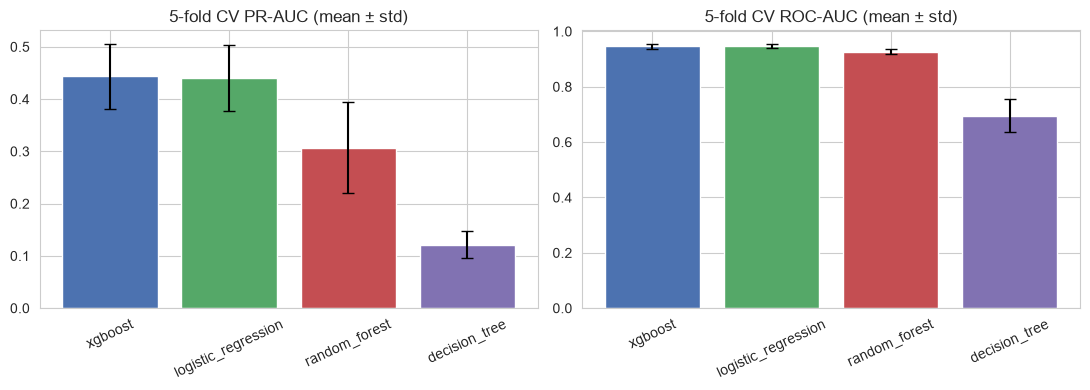

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (metric, std) in zip(ax, [("pr_auc", "pr_std"), ("roc_auc", "roc_std")]):
    a.bar(cv_table.index, cv_table[metric], yerr=cv_table[std], capsize=4,
          color=["#4c72b0", "#55a868", "#c44e52", "#8172b2"])
    a.set_title(f"5-fold CV {metric.replace('_', '-').upper()} (mean ± std)")
    a.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

In [ ]:
# Validation-set view: train on the train part, score on validation (52 frauds only: noisy!)
def recall_in_top(y_true, y_score, frac=0.03):
    k = int(len(y_score) * frac)
    top = np.argsort(-y_score)[:k]
    return y_true[top].sum() / y_true.sum()

rows = []
for name, mk in final_makers.items():
    m = mk().fit(X_train, y_train)
    s = m.predict_proba(X_val)[:, 1]
    rows.append({"model": name,
                 "roc_auc": roc_auc_score(y_val, s),
                 "pr_auc": average_precision_score(y_val, s),
                 "recall_top_3pct": recall_in_top(y_val, s, 0.03),
                 "recall_top_5pct": recall_in_top(y_val, s, 0.05)})
pd.DataFrame(rows).set_index("model").sort_values("pr_auc", ascending=False).round(3)

,roc_auc,pr_auc,recall_top_3pct,recall_top_5pct
model,,,,
xgboost,0.957,0.377,0.596,0.731
logistic_regression,0.957,0.359,0.635,0.731
random_forest,0.929,0.207,0.442,0.577
decision_tree,0.638,0.070,0.288,0.346


In [ ]:
best_name = cv_table.index[0]
best_pr, best_std = cv_table.loc[best_name, "pr_auc"], cv_table.loc[best_name, "pr_std"]

complexity = {"logistic_regression": 1, "decision_tree": 2, "xgboost": 3, "random_forest": 4}
tied = [n for n in cv_table.index if cv_table.loc[n, "pr_auc"] >= best_pr - best_std]
chosen = min(tied, key=lambda n: complexity[n])

print(f"Best mean PR-AUC:       {best_name} ({best_pr:.3f} ± {best_std:.3f})")
print(f"Tied within 1 std:      {tied}")
print(f"Chosen (simplest tied): {chosen}")

Best mean PR-AUC:       xgboost (0.443 ± 0.062)
Tied within 1 std:      ['xgboost', 'logistic_regression']
Chosen (simplest tied): logistic_regression


In [ ]:
# Do the models agree on what matters? Compare top features
names = dv.get_feature_names_out()

lr_m = final_makers["logistic_regression"]().fit(X_train, y_train)
rf_m = final_makers["random_forest"]().fit(X_train, y_train)
xgb_m = final_makers["xgboost"]().fit(X_train, y_train)

importance = pd.DataFrame({
    "logreg_|coef|": pd.Series(np.abs(lr_m[-1].coef_[0]), index=names),
    "forest": pd.Series(rf_m.feature_importances_, index=names),
    "xgboost": pd.Series(xgb_m.feature_importances_, index=names),
})
top = importance.rank(ascending=False).mean(axis=1).sort_values().head(10).index
importance.loc[top].round(3)

,logreg_|coef|,forest,xgboost
merchant_risk_score,0.912,0.151,0.069
cvv_retry_count,0.856,0.150,0.096
ip_country_mismatch,0.586,0.076,0.096
velocity_score,0.842,0.121,0.054
billing_shipping_mismatch,0.482,0.043,0.065
is_new_merchant,0.557,0.029,0.049
auth_method=no_authentication,0.461,0.023,0.057
time_of_day_hour,0.324,0.035,0.031
is_ai_generated_scam_attempt,0.397,0.018,0.054
is_foreign_transaction,0.282,0.022,0.047
